# MASTER_RUN — NoSQL Catalog & CAP Lab
Single entry point cho toàn bộ pipeline: **Environment → Data → Database → Ingestion → NoSQL Ops → CAP → Results → Validation**.

- Cells có **LIVE** chỉ chạy khi cluster khả dụng; ngược lại ghi **SKIPPED** + hướng dẫn khởi động.
- Phần **EVIDENCE** đọc run thật đã commit (label REAL/LEGACY) — không phải selftest.
- Idempotent: chạy lại an toàn (upsert PK, run dir mới theo run_id).

## Section 1 — Environment Setup

In [1]:
"""Phát hiện project root, verify Python + dependencies + services."""
import os, sys, subprocess, importlib.util
from pathlib import Path

def find_root():
    p = Path.cwd()
    for cand in [p] + list(p.parents):
        if (cand / "scripts" / "data_contract.py").exists():
            return cand
    raise RuntimeError("Không tìm thấy project root (scripts/data_contract.py)")

ROOT = find_root()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
os.chdir(ROOT)

STATUS = {}
print("Python:", sys.version.split()[0], "| root:", ROOT)

REQ = ["pandas", "numpy", "yaml", "matplotlib"]
OPT = ["scipy", "cassandra", "pymongo", "nbformat"]
deps = {}
for m in REQ + OPT:
    deps[m] = importlib.util.find_spec(m) is not None
    print(("  OK " if deps[m] else ("  MISSING-REQ " if m in REQ else "  opt-missing ")) + m)
STATUS["deps"] = deps

DOCKER = subprocess.run(["which", "docker"], capture_output=True).returncode == 0
print("docker:", "available" if DOCKER else "NOT FOUND - live experiments sẽ SKIPPED")
STATUS["docker"] = DOCKER

# Kiểm tra kết nối ScyllaDB nhanh (không mở session nặng)
import socket
def _probe(host, port, t=1.0):
    try:
        socket.create_connection((host, port), t).close(); return True
    except OSError:
        return False
cps = os.environ.get("SCYLLA_CONTACT_POINTS", "127.0.0.1").split(",")
SCYLLA_UP = any(_probe(c.strip(), 9042) for c in cps)
MONGO_UP = _probe("127.0.0.1", 27017)
print("scylla 9042:", SCYLLA_UP, "| mongo 27017:", MONGO_UP)
STATUS["scylla_up"], STATUS["mongo_up"] = SCYLLA_UP, MONGO_UP
LIVE_SCYLLA = DOCKER and SCYLLA_UP and deps["cassandra"]
LIVE_MONGO = DOCKER and MONGO_UP and deps["pymongo"]
print("LIVE_SCYLLA:", LIVE_SCYLLA, "| LIVE_MONGO:", LIVE_MONGO)

Python: 3.14.0 | root: $PROJECT_ROOT
  OK pandas
  OK numpy
  OK yaml
  OK matplotlib
  OK scipy
  opt-missing cassandra
  opt-missing pymongo
  OK nbformat
docker: NOT FOUND - live experiments sẽ SKIPPED
scylla 9042: False | mongo 27017: False
LIVE_SCYLLA: False | LIVE_MONGO: False


## Section 2 — Data Preparation
Dataset chung `data/sample/` (origin=simulated — Uyên seeder): products + replay workload.

In [2]:
"""Load + validate products.csv và workload ops."""
import csv
from collections import Counter
from product_catalog import load_products, load_workload_ops, bucket_of

DATA = ROOT / "data" / "sample"
products = load_products(DATA / "products.csv")
ops = load_workload_ops(DATA / "access_log.csv")

pids = [p["product_id"] for p in products]
dup = len(pids) - len(set(pids))
missing = sum(1 for p in products if any(
    v is None or (isinstance(v, str) and v.strip() == "")
    for v in p.values()))
bad_bucket = sum(1 for p in products if bucket_of(p["product_id"]) != p["bucket"])
cats = Counter(p["category_id"] for p in products)
op_dist = Counter(o[0] for o in ops)

DATA_OK = dup == 0 and missing == 0 and bad_bucket == 0
print(f"products: {len(products)} | categories: {len(cats)} | dup_pid: {dup} | "
      f"missing_fields: {missing} | bad_bucket: {bad_bucket}")
print("workload ops:", dict(op_dist), "| top categories:", cats.most_common(3))
assert DATA_OK, "Dataset lỗi - kiểm tra lại products.csv"
STATUS["data_prep"] = "PASS" if DATA_OK else "FAIL"

products: 5000 | categories: 20 | dup_pid: 0 | missing_fields: 0 | bad_bucket: 0
workload ops: {'READ': 13481, 'WRITE': 1519} | top categories: [('pets', 1774), ('gaming', 747), ('health', 440)]


## Section 3 — Database Initialization *(LIVE)*
Cần: `docker compose -f docker/scylla.yml up -d` + `nodetool status` = 3/3 UN + `scylla-driver`.

In [3]:
"""Khởi tạo keyspace + tables nếu cluster LIVE (idempotent: IF NOT EXISTS)."""
DB_STATUS = "SKIPPED"
if LIVE_SCYLLA:
    from lab_connect import connect, ensure_keyspace, wait_cluster_ready
    cluster, session = connect()
    n_up = wait_cluster_ready(cluster, min_up=1, timeout_s=10, label="init")
    if n_up < 1:
        DB_STATUS = "FAIL: cluster không UP"; LIVE_SCYLLA = False
    else:
        ensure_keyspace(session, "catalog")   # NTS datacenter1 RF=3
        session.execute("""CREATE TABLE IF NOT EXISTS products_by_category (
            category_id text, added_at bigint, product_id text,
            name text, brand text, price double, currency text,
            stock int, rating double, attributes text,
            PRIMARY KEY ((category_id), added_at, product_id))""")
        session.execute("""CREATE TABLE IF NOT EXISTS products_bucketed (
            category_id text, bucket int, added_at bigint, product_id text,
            name text, brand text, price double, currency text,
            stock int, rating double, attributes text,
            PRIMARY KEY ((category_id, bucket), added_at, product_id))""")
        DB_STATUS = f"PASS (nodes up={n_up})"
else:
    print("SKIPPED — cluster không khả dụng. Khởi động:")
    print("  docker network create --subnet=10.88.88.0/24 lab-net")
    print("  docker compose -f docker/scylla.yml up -d && pip install scylla-driver")
STATUS["db_init"] = DB_STATUS
print("db_init:", DB_STATUS)

SKIPPED — cluster không khả dụng. Khởi động:
  docker network create --subnet=10.88.88.0/24 lab-net
  docker compose -f docker/scylla.yml up -d && pip install scylla-driver
db_init: SKIPPED


## Section 4 — Data Ingestion *(LIVE)*
Idempotent: INSERT theo full PK → re-run upsert cùng bản ghi, không duplicate.

In [4]:
"""Seed products vào cluster (nếu LIVE). Dùng prepared INSERT - idempotent."""
INGEST = "SKIPPED"
if LIVE_SCYLLA:
    insert_a = session.prepare(
        "INSERT INTO products_by_category (category_id, added_at, product_id,"
        " name, brand, price, currency, stock, rating, attributes)"
        " VALUES (?,?,?,?,?,?,?,?,?,?)")
    for p in products:
        session.execute(insert_a, tuple(p[k] for k in (
            "category_id","added_at","product_id","name","brand",
            "price","currency","stock","rating","attributes")))
    cnt = session.execute(
        "SELECT COUNT(*) FROM products_by_category").one()[0]
    INGEST = f"PASS ({cnt} rows in products_by_category)"
    assert cnt == len(products), "count mismatch sau ingest"
STATUS["ingest"] = INGEST
print("ingest:", INGEST)

ingest: SKIPPED


## Section 5 — Core NoSQL Operations
- **LIVE**: chạy `e1a`/`e1b` (replay workload) + `lwt` + `counter` qua subprocess (standalone scripts đúng thiết kế).
- **OFFLINE**: SKIP + trình bày evidence đã commit ở Section 7.

In [5]:
"""Chạy experiment scripts nếu LIVE; giới hạn --limit nhỏ cho demo."""
import subprocess, sys
NOSQL = {}
def _run(script, *args):
    r = subprocess.run([sys.executable, str(ROOT/"scripts"/script), *args],
                       capture_output=True, text=True, cwd=ROOT, timeout=900)
    return "PASS" if r.returncode == 0 else f"FAIL: {r.stderr[-200:]}"
if LIVE_SCYLLA:
    NOSQL["e1a"] = _run("e1a_zipf_workload.py", "--limit", "500")
    NOSQL["e1b"] = _run("e1b_bucketing_workload.py", "--limit", "500")
    NOSQL["lwt"] = _run("lwt_experiment.py")
    NOSQL["counter"] = _run("counter_experiment.py")
else:
    for k in ("e1a","e1b","lwt","counter"): NOSQL[k] = "SKIPPED (no live cluster)"
    print("SKIPPED — evidence từ run đã commit sẽ hiện ở Section 7")
STATUS["nosql_ops"] = NOSQL
for k, v in NOSQL.items(): print(f"  {k}: {v}")

SKIPPED — evidence từ run đã commit sẽ hiện ở Section 7
  e1a: SKIPPED (no live cluster)
  e1b: SKIPPED (no live cluster)
  lwt: SKIPPED (no live cluster)
  counter: SKIPPED (no live cluster)


## Section 6 — CAP Theorem Experiments
**Phân biệt rõ**: lý thuyết (markdown) vs observed (run thật). LIVE chạy `cap_matrix_e2_e5` (health gate + heal-wait đã fix). OFFLINE đọc run REAL đã commit ngày 18/11 (legacy contract — gắn nhãn rõ).

In [6]:
"""CAP matrix: LIVE rerun hoặc phân tích run thật đã commit."""
CAP = {}
if LIVE_SCYLLA:
    CAP["matrix"] = _run("cap_matrix_e2_e5.py", "--duration", "30",
                         "--partition-at", "10", "--heal-at", "20")
else:
    # REAL committed evidence (legacy contract) - KHÔNG phải selftest
    from analyze_committed_runs import analyze_run
    for exp, run in [("CAP_ONE","20261118164217_51d70a18"),
                     ("CAP_QUORUM","20261118164246_1e06bf4f"),
                     ("CAP_ALL","20261118164314_7e93eceb")]:
        r = analyze_run(str(ROOT/"experiments"/exp/run))
        ph = r.get("phases", {})
        label = "INVALID RUN (setup defect - không phải CAP evidence)" \
                if exp == "CAP_ALL" else "REAL evidence"
        CAP[exp] = {
            "status": label, "run_id": run, "n_ops": r["n_ops"],
            "pre_ok%": ph.get("pre",{}).get("ok_pct"),
            "partition_ok%": ph.get("during",{}).get("ok_pct"),
            "post_ok%": ph.get("post",{}).get("ok_pct")}
    import pandas as pd
    display(pd.DataFrame(CAP).T)
STATUS["cap"] = CAP

,status,run_id,n_ops,pre_ok%,partition_ok%,post_ok%
CAP_ONE,REAL evidence,20261118164217_51d70a18,4008,100.0,100.0,100.0
CAP_QUORUM,REAL evidence,20261118164246_1e06bf4f,3916,100.0,100.0,100.0
CAP_ALL,INVALID RUN (setup defect - không phải CAP evi...,20261118164314_7e93eceb,4158,0.0,0.0,0.0


## Section 7 — Results & Evaluation
Pipeline Uyên (`src/catalog_analysis`) chạy trên **selftest contract v2** (SYNTHETIC — kiểm chứng consumption) + analysis của **committed real runs** (REAL/LEGACY).

In [7]:
"""Chạy analysis pipeline thật của Uyên + tổng hợp committed runs."""
import json, tempfile
# (a) selftest v2 -> 3 module Uyên (contract verification, SYNTHETIC)
from selftest_contract import main as _st
import io, contextlib, sys as _sys
_sys.argv = ["selftest_contract.py", "--out", str(tempfile.mkdtemp(prefix="mr_selftest_"))]
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    _st()
SELFTEST_DIR = Path(buf.getvalue().strip().splitlines()[-1])
print("selftest dir:", SELFTEST_DIR)

OUT = ROOT / "results" / "master_run"; OUT.mkdir(parents=True, exist_ok=True)
from src.catalog_analysis import top_partitions, stale_read, bootstrap_ci
RES = {}
RES["top_partitions"] = top_partitions.run(SELFTEST_DIR, OUT/"selftest_top")
RES["stale_read"] = stale_read.run(SELFTEST_DIR, OUT/"selftest_stale")
RES["bootstrap_ci"] = bootstrap_ci.run(SELFTEST_DIR, OUT/"selftest_ci")
print("selftest → run consistency:",
      RES["top_partitions"]["run"]["consistency"], "| origin:",
      RES["top_partitions"]["origin"], "| stale_reads:",
      RES["stale_read"]["by_consistency_level"]["ONE"]["stale_reads"])

# (b) committed REAL runs analysis
from analyze_committed_runs import main as _ana
_sys.argv = ["analyze", "--experiments", "experiments",
             "--out", str(OUT/"committed")]
with contextlib.redirect_stdout(io.StringIO()):
    _ana()
committed = json.load(open(OUT/"committed"/"analysis.json"))
print(f"committed runs analyzed: {len(committed)} (REAL, legacy contract)")
STATUS["analysis"] = RES

selftest dir: <tmpdir>/SELFTEST/20261120052847_3141d42e


selftest → run consistency: ok | origin: synthetic | stale_reads: 1
committed runs analyzed: 9 (REAL, legacy contract)


cap_success_phases.png


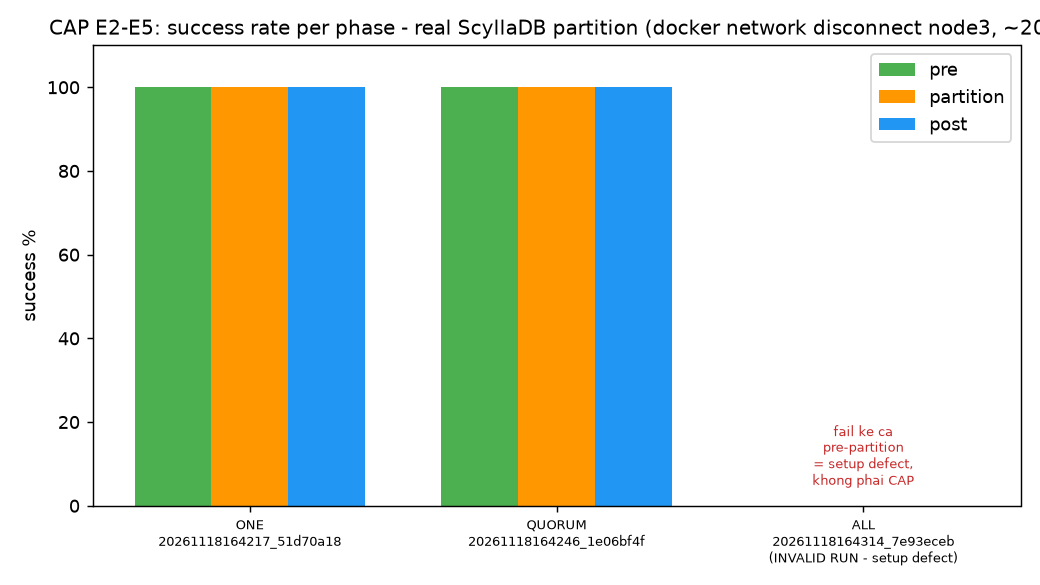

e1_latency_cdf.png


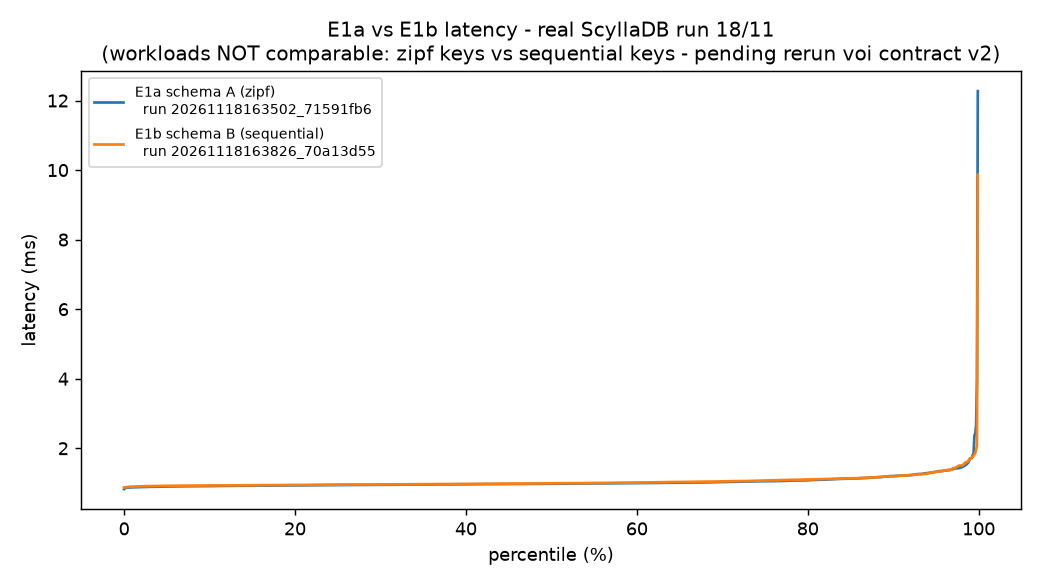

e6_failover_timeline.png


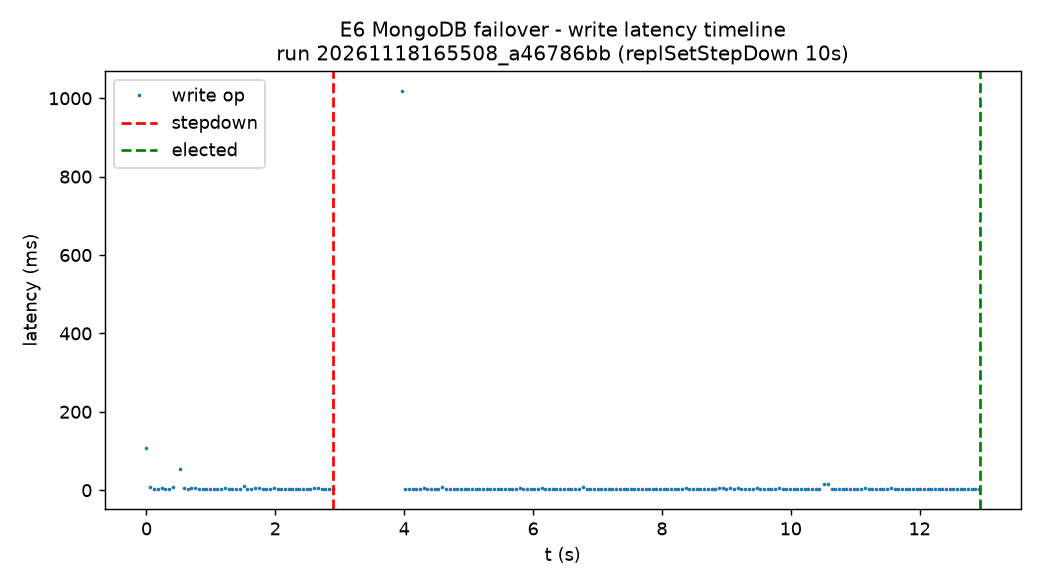

lwt_outcome.png


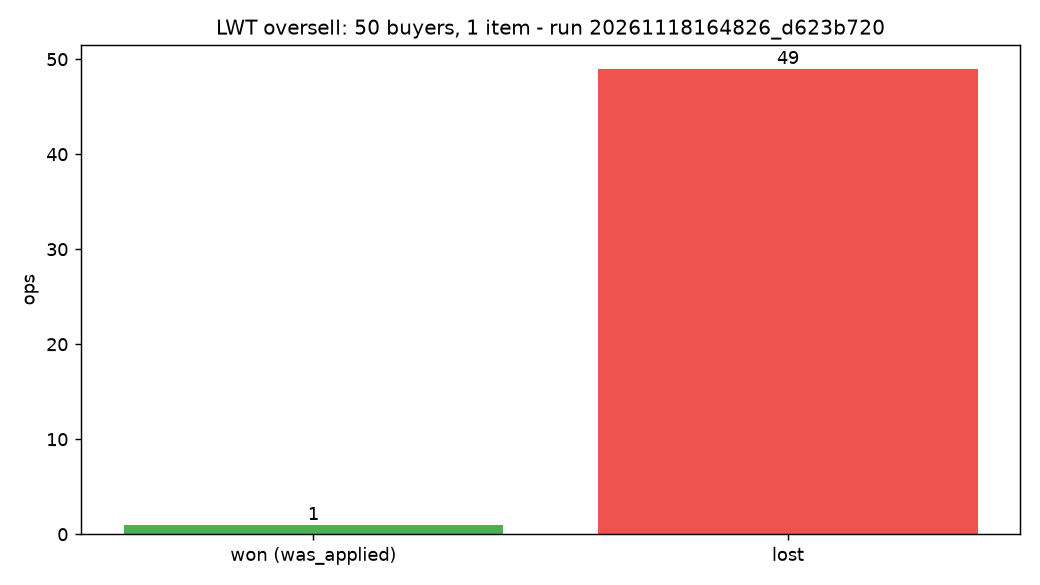

In [8]:
"""Charts từ real committed data + hiển thị."""
import subprocess, sys
subprocess.run([sys.executable, "scripts/chart_committed_runs.py",
                "--out", str(OUT/"charts")], cwd=ROOT, check=True,
               capture_output=True)
from IPython.display import Image, display
for png in sorted((OUT/"charts").glob("*.png")):
    print(png.name); display(Image(filename=str(png)))

## Section 8 — Final Validation & Execution Report

In [9]:
"""Tổng hợp PASS/FAIL/SKIPPED - không auto-PASS chỉ vì cell chạy xong."""
import json
report = {
    "environment": "PASS" if all(STATUS["deps"][m] for m in
                    ["pandas","numpy","yaml","matplotlib"]) else "FAIL",
    "data_preparation": STATUS.get("data_prep"),
    "database_initialization": STATUS.get("db_init"),
    "data_ingestion": STATUS.get("ingest"),
    "nosql_operations": STATUS.get("nosql_ops"),
    "cap_experiments": STATUS.get("cap"),
    "analysis_pipeline": ("PASS" if STATUS.get("analysis", {})
                          .get("top_partitions",{})
                          .get("run",{}).get("consistency") == "ok"
                          else "FAIL"),
    "evidence_charts": ("PASS" if list((OUT/"charts").glob("*.png"))
                        else "FAIL"),
}
n_pass = sum(1 for v in report.values()
             if isinstance(v, str) and v.startswith("PASS"))
n_skip = sum(1 for v in report.values() if "SKIP" in str(v))
n_fail = sum(1 for v in report.values() if "FAIL" in str(v))
for k, v in report.items(): print(f"  {k}: {v}")
print(f"\nSUMMARY: PASS={n_pass} SKIPPED={n_skip} FAIL={n_fail}")
report["_meta"] = {"root": str(ROOT), "note":
    "SKIPPED = thiếu cluster (Docker + driver). PASS analysis = selftest "
    "synthetic + committed real evidence, không phải live rerun."}
with open(OUT / "master_run_report.json", "w") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
print("report:", OUT / "master_run_report.json")

  environment: PASS
  data_preparation: PASS
  database_initialization: SKIPPED
  data_ingestion: SKIPPED
  nosql_operations: {'e1a': 'SKIPPED (no live cluster)', 'e1b': 'SKIPPED (no live cluster)', 'lwt': 'SKIPPED (no live cluster)', 'counter': 'SKIPPED (no live cluster)'}
  cap_experiments: {'CAP_ONE': {'status': 'REAL evidence', 'run_id': '20261118164217_51d70a18', 'n_ops': 4008, 'pre_ok%': 100.0, 'partition_ok%': 100.0, 'post_ok%': 100.0}, 'CAP_QUORUM': {'status': 'REAL evidence', 'run_id': '20261118164246_1e06bf4f', 'n_ops': 3916, 'pre_ok%': 100.0, 'partition_ok%': 100.0, 'post_ok%': 100.0}, 'CAP_ALL': {'status': 'INVALID RUN (setup defect - không phải CAP evidence)', 'run_id': '20261118164314_7e93eceb', 'n_ops': 4158, 'pre_ok%': 0.0, 'partition_ok%': 0.0, 'post_ok%': 0.0}}
  analysis_pipeline: PASS
  evidence_charts: PASS

SUMMARY: PASS=4 SKIPPED=3 FAIL=0
report: $PROJECT_ROOT/results/master_run/master_run_report.json
